# Assignment 2 - Modelling and Evaluation

In this notebook, we use the cleaned output from the data pipeline to see whether we can flag train observations that are likely to be crowded. We are not trying to let a model make timetable decisions by itself. Instead, we compare a simple baseline with two different models and ask which one gives the operations team the most useful starting point for a human review.


## Scope and evaluation contract

### What decision are we supporting?

The NSW train operations team needs a practical way to decide which services may need a closer look for crowding. Our model predicts `Crowded` for one station-stop observation at a time. A value of 1 means the recorded status was `FEW_SEATS_AVAILABLE` or `STANDING_ROOM_ONLY`; a value of 0 means there were many seats available.

### What did we carry forward from Assignment 1?

Our Stage 1 work showed that a reproducible pipeline and clear cleaning evidence matter. For Assignment 2, we strengthened that handover by making the pipeline create and save the exact CSV used here, instead of loading an earlier file directly. This gives us one clear path from raw data to final results.

### How will we judge the models?

The most important mistake for this stakeholder is a false negative: a crowded observation is predicted as not crowded, so it may never be reviewed. For that reason, crowded-class recall is our primary metric. We still report precision and F1-score, because a model that produces too many false alarms can waste staff time. Accuracy is included for context only, because almost every record is not crowded and accuracy by itself would give a misleadingly positive picture.

We use the same stratified 80/20 train/test split for every model, with `random_state=42`. The split happens before preprocessing, and the preparation steps are learned from training data only. This makes the comparison fair and reproducible.


### Our baseline and model choices

We start with a majority-class baseline that always predicts the most common answer, which is not crowded. It gives us a useful reality check: if a more advanced model cannot beat that baseline in a meaningful way, it is not adding value.

We then compare Logistic Regression and Random Forest. Logistic Regression is a simpler model that gives us a direct probability of crowding from the available features. Random Forest combines many decision trees and can pick up more complicated relationships. They are meaningfully different approaches, but both use the same features, preprocessing, train/test split and evaluation metrics so we can compare them fairly.

Missing categorical values are filled with the most common training value and then one-hot encoded. Missing numeric values are filled with the training median and scaled. We use balanced class weights because crowded observations make up only a small part of the dataset. These choices are kept fixed rather than repeatedly tuned until we get a nicer score.

### Why the models may behave differently

Logistic Regression makes one overall, additive estimate of crowding from the available predictors. This makes its probabilities and threshold choices relatively easy to explain to the operations team. Its limitation is that it may miss more complicated patterns, such as a particular combination of line, direction and station that matters only at some times. With balanced class weights, it is deliberately encouraged to flag the less-common crowded class, which can improve recall but also create more false alarms.

Random Forest combines many decision trees, so it can capture non-linear patterns and interactions without us specifying them in advance. That may make it more selective when it flags crowding. However, it is less transparent than Logistic Regression: it is harder to explain one individual prediction, and its apparent performance may be influenced by repeated service, station or trip patterns in the random split. It therefore needs the same careful leakage checks and a grouped or later-time validation before we treat it as evidence of performance on genuinely new services.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# This must be the output produced by 01_data_pipeline.ipynb.
possible_paths = [
    Path("../data/processed/train_occupancy_model_ready.csv"),
    Path("data/processed/train_occupancy_model_ready.csv"),
    Path("COMP5310_A2/data/processed/train_occupancy_model_ready.csv"),
]
data_path = next((path for path in possible_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Model-ready data was not found. Run 01_data_pipeline.ipynb first."
    )

train_df = pd.read_csv(data_path)
print("Dataset loaded successfully.")
print("File location:", data_path)
print("Shape:", train_df.shape)
display(train_df.head())


Dataset loaded successfully.
File location: ..\data\processed\train_occupancy_model_ready.csv
Shape: (49927, 17)


,day,Actual.Stop.Station,Actual.Station.Arrv.Time,Actual.Station.Dprt.Time,Segment.Direction,Trip.Name,Service.Line,Orig..Station,Dest..Station,Leading.Set.Type,Node.Seq.Order,Actual.Station.Dprt.Time.Band,Occupancy Status,Occupancy Range,Arrival_Clean,Departure_Clean,Crowded
0,9,Miranda,2017-01-10 00:18:17,2017-01-10 00:19:04,Down,620S,Illawarra,Central,Cronulla,T,18,00:15-00:29,MANY_SEATS_AVAILABLE,Low: 0-399,2017-01-10 00:18:17,2017-01-10 00:18:17,0
1,13,Beecroft,2017-01-13 08:05:59,2017-01-13 08:06:56,Down,152C,North via Macquarie Park,Central,Hornsby,A,16,08:00-08:14,MANY_SEATS_AVAILABLE,Low: 0-399,2017-01-13 08:05:59,2017-01-13 08:05:59,0
2,12,Arncliffe,2017-01-12 07:22:51,2017-01-12 07:23:36,Down,607B,Illawarra,Central,Waterfall,T,6,07:15-07:29,MANY_SEATS_AVAILABLE,Low: 0-399,2017-01-12 07:22:51,2017-01-12 07:22:51,0
3,13,Dulwich Hill,2017-01-13 07:20:39,2017-01-13 07:21:53,Down,58-F,Bankstown,Central,Birrong,A,7,07:15-07:29,MANY_SEATS_AVAILABLE,Low: 0-399,2017-01-13 07:20:39,2017-01-13 07:20:39,0
4,11,Belmore,2017-01-11 18:38:28,2017-01-11 18:39:07,Up,33-P,Bankstown,Birrong,Central,K,7,18:30-18:44,MANY_SEATS_AVAILABLE,Low: 0-399,2017-01-11 18:38:28,2017-01-11 18:38:28,0


In [2]:
# Validate the target created in the pipeline.
if "Crowded" not in train_df.columns:
    raise ValueError("The pipeline output has no Crowded target. Re-run 01_data_pipeline.ipynb.")

expected_target = train_df["Occupancy Status"].isin(
    ["FEW_SEATS_AVAILABLE", "STANDING_ROOM_ONLY"]
).astype(int)
assert train_df["Crowded"].equals(expected_target), "Crowded target does not match Occupancy Status"

print(train_df["Crowded"].value_counts().rename_axis("Crowded").to_frame("records"))
print(train_df["Crowded"].value_counts(normalize=True).mul(100).round(2))


         records
Crowded         
0          47933
1           1994
Crowded
0    96.01
1     3.99
Name: proportion, dtype: float64


In [3]:
# The target was created and checked in the data pipeline.
# This cell retains a clear record of the target definition for the report.
target_definition = {
    1: "FEW_SEATS_AVAILABLE or STANDING_ROOM_ONLY",
    0: "MANY_SEATS_AVAILABLE",
}
target_definition


{1: 'FEW_SEATS_AVAILABLE or STANDING_ROOM_ONLY', 0: 'MANY_SEATS_AVAILABLE'}

In [4]:
# Remove outcome fields and variables that are unavailable or unsafe at prediction time.
drop_cols = [
    "Occupancy Status",       # Source used to derive the target.
    "Occupancy Range",        # Closely related to the target: target leakage risk.
    "Actual.Station.Arrv.Time",  # Actual, not confirmed available at decision time.
    "Actual.Station.Dprt.Time",  # Actual, not confirmed available at decision time.
    "Actual.Station.Dprt.Time.Band",  # Derived from actual departure time.
    "Arrival_Clean",
    "Departure_Clean",
    "Crowded",
]

X = train_df.drop(columns=drop_cols)
y = train_df["Crowded"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values in features:", X.isna().sum().sum())


Feature shape: (49927, 9)
Target shape: (49927,)
Missing values in features: 427


In [5]:
# Check which features have missing values
missing = X.isna().sum().sort_values(ascending=False)
print(missing[missing > 0])

Orig..Station          79
Segment.Direction      78
Leading.Set.Type       76
Actual.Stop.Station    72
Dest..Station          63
Service.Line           59
dtype: int64


In [6]:
# Timestamp fields were excluded above because their availability is not confirmed.
# Trip.Name is retained for this initial benchmark, but its repeated-service nature
# is audited after splitting and must be reassessed before deployment.
categorical_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

print("Categorical features:", categorical_cols)
print("Numerical features:", numeric_cols)
print("Rows:", len(X))


Categorical features: ['Actual.Stop.Station', 'Segment.Direction', 'Trip.Name', 'Service.Line', 'Orig..Station', 'Dest..Station', 'Leading.Set.Type']
Numerical features: ['day', 'Node.Seq.Order']
Rows: 49927


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(4))

Training rows: 39941
Testing rows: 9986

Training target proportions:
Crowded
0    0.9601
1    0.0399
Name: proportion, dtype: float64

Testing target proportions:
Crowded
0    0.96
1    0.04
Name: proportion, dtype: float64


### Check for leakage and whether features would be available

We remove the outcome fields and actual timestamps before fitting the models. `Occupancy Status` directly creates the target, while `Occupancy Range` is closely related to it, so either one would give the model information it should not have. We also leave out actual arrival and departure times because we have not established that they would be known when an operations team needs to make a decision.

We keep `Trip.Name` in this first benchmark but check how it behaves across the split. If the same trip appears in training and testing, the result may partly reflect how well the model recognises a known service rather than how well it generalises to a brand-new one. That is a limitation we need to be honest about when reporting the results.


In [8]:
if "Trip.Name" in X_train.columns:
    train_trips = set(X_train["Trip.Name"].dropna())
    test_trips = set(X_test["Trip.Name"].dropna())
    shared_trips = train_trips.intersection(test_trips)
    print(f"Unique training trips: {len(train_trips):,}")
    print(f"Unique testing trips: {len(test_trips):,}")
    print(f"Trip.Name values appearing in both splits: {len(shared_trips):,}")
    print("Interpretation: this random-split benchmark includes observations from shared services;")
    print("it is not evidence of performance for completely unseen Trip.Name values.")


Unique training trips: 3,530
Unique testing trips: 2,976
Trip.Name values appearing in both splits: 2,919
Interpretation: this random-split benchmark includes observations from shared services;
it is not evidence of performance for completely unseen Trip.Name values.


In [9]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("numeric", numeric_pipeline, numeric_cols)
])

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numeric_cols))
print("Preprocessing setup complete.")


Categorical features: 7
Numerical features: 2
Preprocessing setup complete.


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9368

Confusion matrix:
[[9000  587]
 [  44  355]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      9587
           1       0.38      0.89      0.53       399

    accuracy                           0.94      9986
   macro avg       0.69      0.91      0.75      9986
weighted avg       0.97      0.94      0.95      9986



In [11]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_pred))
print("\nClassification report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Accuracy: 0.9675

Confusion matrix:
[[9576   11]
 [ 314   85]]

Classification report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      9587
           1       0.89      0.21      0.34       399

    accuracy                           0.97      9986
   macro avg       0.93      0.61      0.66      9986
weighted avg       0.96      0.97      0.96      9986



In [12]:

from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_pred))
print("\nClassification report:")
print(classification_report(y_test, baseline_pred, zero_division=0))


Baseline accuracy: 0.96

Confusion matrix:
[[9587    0]
 [ 399    0]]

Classification report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      9587
           1       0.00      0.00      0.00       399

    accuracy                           0.96      9986
   macro avg       0.48      0.50      0.49      9986
weighted avg       0.92      0.96      0.94      9986



In [13]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, predictions in [
    ("Baseline", baseline_pred),
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Crowded Precision": precision_score(y_test, predictions, zero_division=0),
        "Crowded Recall": recall_score(y_test, predictions, zero_division=0),
        "Crowded F1": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df.round(4)


,Model,Accuracy,Crowded Precision,Crowded Recall,Crowded F1
0,Baseline,0.9600,0.0000,0.0000,0.0000
1,Logistic Regression,0.9368,0.3769,0.8897,0.5295
2,Random Forest,0.9675,0.8854,0.2130,0.3434


## Visual comparison of the model metrics

The tables give us the exact values, but the two charts below make the story easier to explain. The first chart separates overall accuracy from the crowded-class metrics, because accuracy is high for every model in this imbalanced dataset and would otherwise hide the recall and precision differences. The second chart translates the confusion matrices into the two decisions the team actually cares about: how many false alarms they may need to investigate and how many crowded observations the model misses.


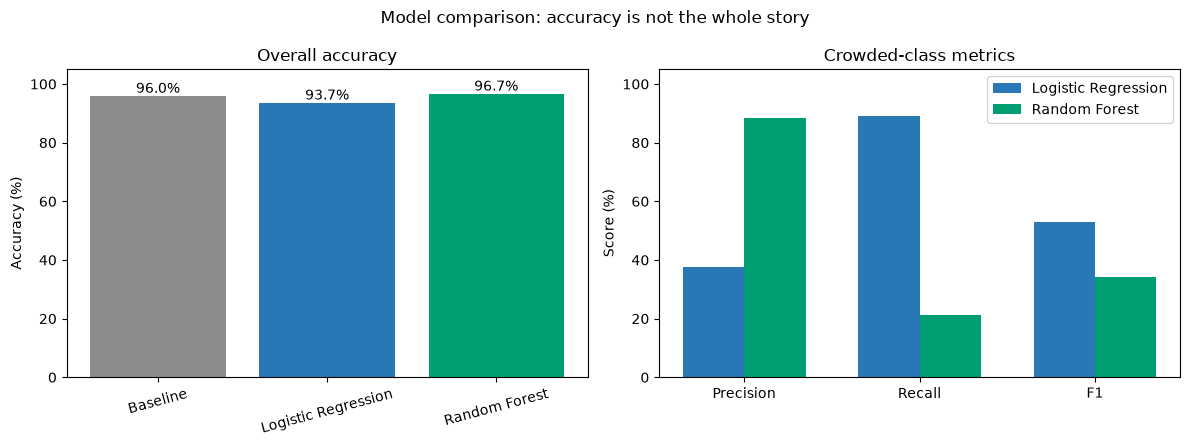

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt


# Accuracy is shown separately because it is misleadingly high for every model.
model_order = ["Baseline", "Logistic Regression", "Random Forest"]
plot_results = results_df.set_index("Model").loc[model_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
accuracy_values = plot_results["Accuracy"] * 100
bars = axes[0].bar(model_order, accuracy_values, color=["#8C8C8C", "#2878B5", "#009E73"])
axes[0].set_title("Overall accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis="x", rotation=15)
for bar, value in zip(bars, accuracy_values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 1, f"{value:.1f}%", ha="center")

candidate_results = plot_results.loc[["Logistic Regression", "Random Forest"]]
metric_labels = ["Crowded Precision", "Crowded Recall", "Crowded F1"]
x = np.arange(len(metric_labels))
width = 0.35
axes[1].bar(x - width / 2, candidate_results.loc["Logistic Regression", metric_labels] * 100, width, label="Logistic Regression", color="#2878B5")
axes[1].bar(x + width / 2, candidate_results.loc["Random Forest", metric_labels] * 100, width, label="Random Forest", color="#009E73")
axes[1].set_title("Crowded-class metrics")
axes[1].set_ylabel("Score (%)")
axes[1].set_ylim(0, 105)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Precision", "Recall", "F1"])
axes[1].legend()
fig.suptitle("Model comparison: accuracy is not the whole story")
fig.tight_layout()
plt.show()


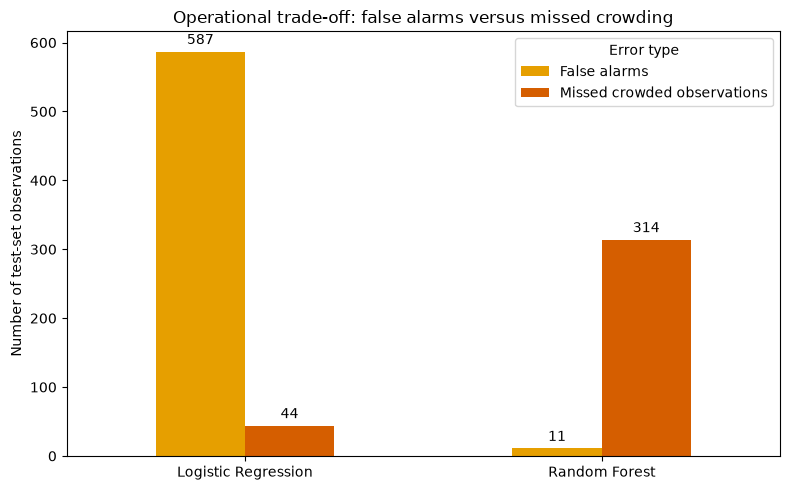

,Model,False alarms,Missed crowded observations
0,Logistic Regression,587,44
1,Random Forest,11,314


In [15]:
# This chart shows the practical trade-off between the two candidate models.
error_rows = []
for name, pred in [("Logistic Regression", y_pred), ("Random Forest", rf_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    error_rows.append({"Model": name, "False alarms": fp, "Missed crowded observations": fn})
error_tradeoff = pd.DataFrame(error_rows)

ax = error_tradeoff.set_index("Model").plot(kind="bar", figsize=(8, 5), color=["#E69F00", "#D55E00"], rot=0)
ax.set_title("Operational trade-off: false alarms versus missed crowding")
ax.set_xlabel("")
ax.set_ylabel("Number of test-set observations")
ax.legend(title="Error type")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()
display(error_tradeoff)


### Keep a clear record of the experiment and look at thresholds

The table below records the models, shared feature set, settings and primary metric so the final comparison is easy to trace. We also test a few Logistic Regression thresholds. A lower threshold catches more possible crowding but creates more false alarms; a higher threshold reduces unnecessary flags but risks missing genuine crowding. The numbers help the stakeholder see the trade-off instead of treating 0.50 as automatically correct.


In [16]:
experiment_log = pd.DataFrame([
    {"Approach": "Baseline", "Features": "Same 9 predictors", "Settings": "DummyClassifier(most_frequent)", "Primary metric": "Crowded recall"},
    {"Approach": "Logistic Regression", "Features": "Same 9 predictors", "Settings": "balanced classes, max_iter=1000, random_state=42", "Primary metric": "Crowded recall"},
    {"Approach": "Random Forest", "Features": "Same 9 predictors", "Settings": "200 trees, balanced classes, random_state=42", "Primary metric": "Crowded recall"},
])
display(experiment_log)
display(results_df.round(4))


,Approach,Features,Settings,Primary metric
0,Baseline,Same 9 predictors,DummyClassifier(most_frequent),Crowded recall
1,Logistic Regression,Same 9 predictors,"balanced classes, max_iter=1000, random_state=42",Crowded recall
2,Random Forest,Same 9 predictors,"200 trees, balanced classes, random_state=42",Crowded recall


,Model,Accuracy,Crowded Precision,Crowded Recall,Crowded F1
0,Baseline,0.9600,0.0000,0.0000,0.0000
1,Logistic Regression,0.9368,0.3769,0.8897,0.5295
2,Random Forest,0.9675,0.8854,0.2130,0.3434


In [17]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

logistic_probability = model.predict_proba(X_test)[:, 1]
threshold_rows = []
for threshold in [0.25, 0.50, 0.75]:
    threshold_pred = (logistic_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, threshold_pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Crowded precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Crowded recall": recall_score(y_test, threshold_pred, zero_division=0),
        "False alarms": fp,
        "Missed crowded observations": fn,
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))


,Threshold,Crowded precision,Crowded recall,False alarms,Missed crowded observations
0,0.25,0.2093,0.9348,1409,26
1,0.50,0.3769,0.8897,587,44
2,0.75,0.5329,0.7519,263,99


In [18]:

from sklearn.metrics import confusion_matrix

for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred)
]:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    print(name)
    print("False alarms:", fp)
    print("Missed crowded observations:", fn)
    print("Correctly identified crowded observations:", tp)
    print()


Logistic Regression
False alarms: 587
Missed crowded observations: 44
Correctly identified crowded observations: 355

Random Forest
False alarms: 11
Missed crowded observations: 314
Correctly identified crowded observations: 85



## Interpretation of the verified results

Use the freshly computed results and error tables above. Recall determines how many crowded observations are identified, while precision determines the review workload. The grouped check below tests sensitivity to shared trip identifiers; neither split is a chronological future-data evaluation.

## Recommendation for the stakeholder

For an initial crowding-review process, we would recommend Logistic Regression if the operations team agrees that missing crowding is more costly than investigating false alarms. Its job would be to flag observations for a human to look at, not to automatically change a timetable, add carriages or make a service decision.

Random Forest is an alternative if the team has very limited capacity to investigate flags and false alarms are especially expensive. However, using it would mean accepting that more than half of the crowded observations in this test set were missed. Before either approach is used outside this project, the team should agree on the cost of both error types, test the model on later periods and confirm which features are genuinely available when a decision is needed.


## Model card: Train crowding classification

**Intended use:** Support preliminary investigation of train services that may experience crowding. Predictions are decision-support signals, not automatic instructions to change capacity or timetables.

**Target and unit of prediction:** The binary `Crowded` outcome for an individual train observation, derived from the recorded occupancy status.

**Data:** The cleaned NSW Train Occupancy dataset. The current experiment uses a stratified 80/20 train/test split with `random_state=42`.

**Models evaluated:** Logistic Regression and Random Forest, compared against a majority-class baseline. Preprocessing is fitted within a pipeline using training data.

**Test-set performance:** See the computed results table and grouped sensitivity check. These outputs are regenerated each run.

**Recommended interpretation:** Neither model is ready to deploy on unseen services: grouped recall is only 20.00% for Logistic Regression and 3.08% for Random Forest. Logistic Regression is the stronger research candidate under the recall priority. Confirm feature availability, repeat grouped evaluation and validate on later data before proposing an operational pilot.

**Important failure modes:** False alarms may trigger unnecessary investigations; missed crowded observations may leave genuine crowding undetected. Performance on the held-out test set does not guarantee performance on future services.

**Limitations and inappropriate uses:** The model should not be treated as proof of future crowding or used to make automatic operational changes. Further validation across later time periods is required, and predictor availability at the intended decision time must be confirmed.

**Monitoring needs:** Before any operational use, assess performance on later observations, monitor crowded-class precision and recall, review false alarms and missed crowding, and check for changes in data quality or service patterns.

## EDA supporting the modelling decision

We use only the original training subset for these descriptive plots. Crowding rate is the percentage of observations labelled Crowded, not the percentage of train capacity occupied. Group comparisons describe associations rather than causes. Minimum counts reduce unstable rankings but are not significance tests.

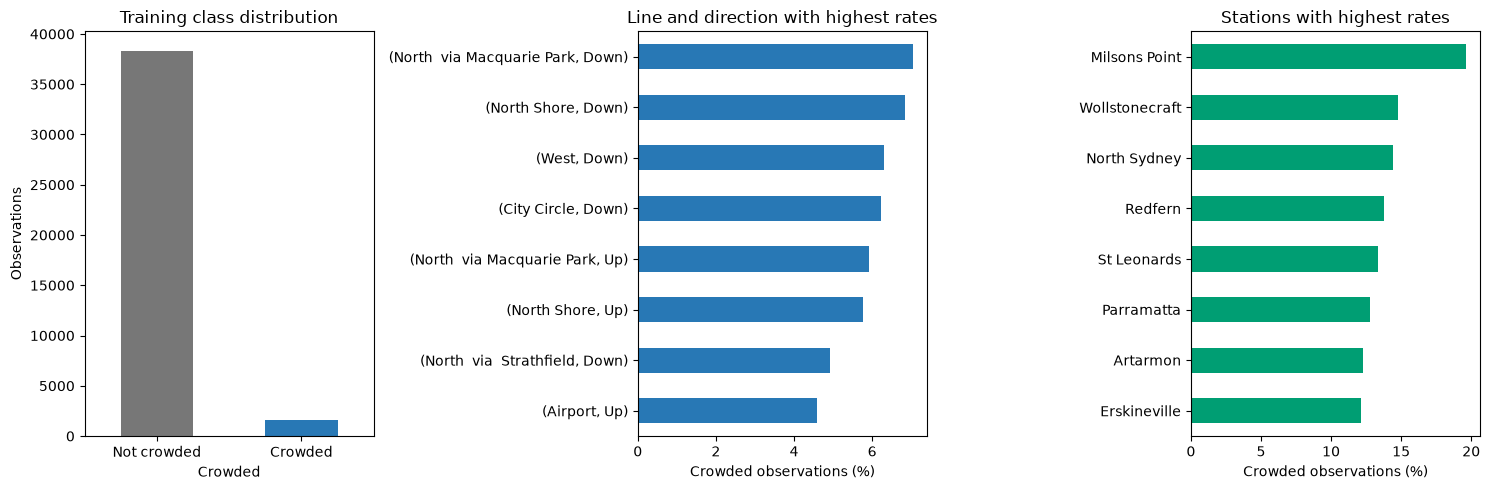

,,records,crowded,rate
Service.Line,Segment.Direction,,,
North via Macquarie Park,Down,1192,84,0.070470
North Shore,Down,1941,133,0.068521
West,Down,2536,160,0.063091
City Circle,Down,1043,65,0.062320
North via Macquarie Park,Up,1252,74,0.059105
North Shore,Up,1859,107,0.057558
North via Strathfield,Down,712,35,0.049157
Airport,Up,1871,86,0.045965


,records,crowded,rate
Actual.Stop.Station,,,
Milsons Point,336,66,0.196429
Wollstonecraft,305,45,0.147541
North Sydney,326,47,0.144172
Redfern,1236,170,0.137540
St Leonards,337,45,0.133531
Parramatta,306,39,0.127451
Artarmon,301,37,0.122924
Erskineville,132,16,0.121212


Crowding affects 3.99% of training observations, so accuracy alone rewards ignoring the minority class.
The highest-rate line-direction and station groups are investigation priorities, not evidence that location causes crowding. Sample counts and repeated observations limit these rankings.


In [19]:
%matplotlib inline
import matplotlib.pyplot as plt
table_dir = data_path.resolve().parents[2] / "results"
table_dir.mkdir(exist_ok=True)
eda = X_train.copy()
eda["Crowded"] = y_train
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
eda["Crowded"].value_counts().sort_index().rename(index={0: "Not crowded", 1: "Crowded"}).plot.bar(ax=axes[0], color=["#777777", "#2878B5"], rot=0)
axes[0].set_title("Training class distribution")
axes[0].set_ylabel("Observations")
line_eda = eda.groupby(["Service.Line", "Segment.Direction"])["Crowded"].agg(records="size", crowded="sum", rate="mean")
line_eda = line_eda.query("records >= 100").sort_values("rate", ascending=False).head(8)
(100 * line_eda["rate"]).sort_values().plot.barh(ax=axes[1], color="#2878B5")
axes[1].set_title("Line and direction with highest rates")
axes[1].set_xlabel("Crowded observations (%)")
axes[1].set_ylabel("")
station_eda = eda.groupby("Actual.Stop.Station")["Crowded"].agg(records="size", crowded="sum", rate="mean")
station_eda = station_eda.query("records >= 100").sort_values("rate", ascending=False).head(8)
(100 * station_eda["rate"]).sort_values().plot.barh(ax=axes[2], color="#009E73")
axes[2].set_title("Stations with highest rates")
axes[2].set_xlabel("Crowded observations (%)")
axes[2].set_ylabel("")
fig.tight_layout()
plt.show()
display(line_eda, station_eda)
line_eda.to_csv(table_dir / "line_eda.csv")
station_eda.to_csv(table_dir / "station_eda.csv")
print(f"Crowding affects {y_train.mean():.2%} of training observations, so accuracy alone rewards ignoring the minority class.")
print("The highest-rate line-direction and station groups are investigation priorities, not evidence that location causes crowding. Sample counts and repeated observations limit these rankings.")


## Explainability and uneven errors

Permutation importance measures how much held-out recall changes when one original feature is shuffled while the fitted model stays fixed. Five repeats with seed 42 describe shuffle variability, not confidence intervals. Correlated predictors can substitute for each other, and shuffling can create unrealistic service combinations. Importance explains model reliance, not a causal effect. We do not use these test-set diagnostics to select features or tune the models.

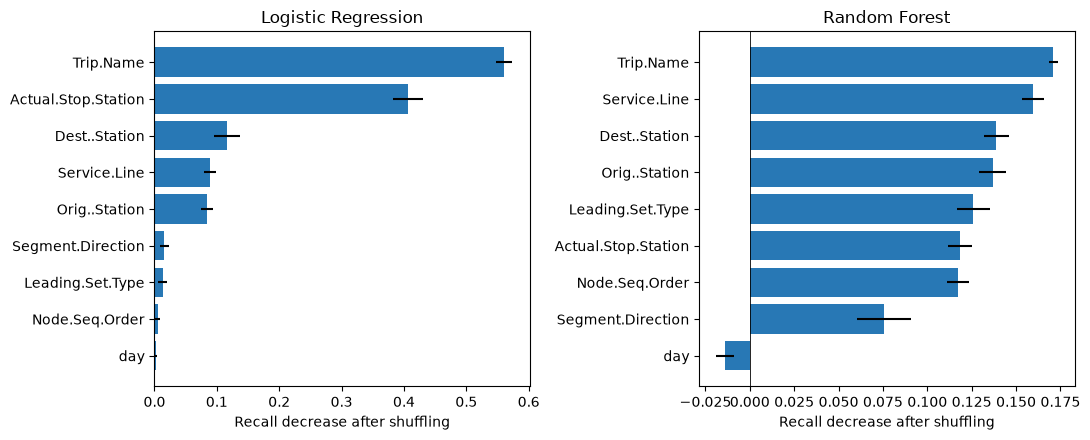

,feature,mean_recall_drop,std,model
3,Trip.Name,0.560902,0.012521,Logistic Regression
1,Actual.Stop.Station,0.406015,0.024144,Logistic Regression
6,Dest..Station,0.116291,0.020088,Logistic Regression
4,Service.Line,0.089223,0.009590,Logistic Regression
5,Orig..Station,0.084712,0.009694,Logistic Regression
2,Segment.Direction,0.016040,0.007367,Logistic Regression
7,Leading.Set.Type,0.013033,0.007333,Logistic Regression
8,Node.Seq.Order,0.005013,0.003544,Logistic Regression
0,day,0.002005,0.001876,Logistic Regression
12,Trip.Name,0.170927,0.002456,Random Forest


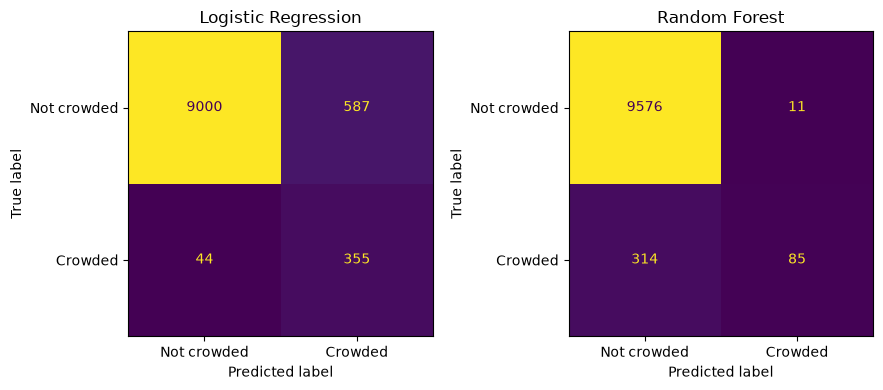

,records,positives,missed,false_alarms,miss_rate,false_alarm_rate
Service.Line,,,,,,
City Circle,665,41,11,116,0.268293,0.185897
North,517,17,6,36,0.352941,0.072000
North Shore,981,62,6,93,0.096774,0.101197
Eastern Suburbs,479,12,4,26,0.333333,0.055675
South,774,26,4,50,0.153846,0.066845
West,1263,71,4,75,0.056338,0.062919
Airport,856,41,3,40,0.073171,0.049080
North via Strathfield,348,13,2,10,0.153846,0.029851
North via Macquarie Park,642,41,2,45,0.048780,0.074875


In [20]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
importance_rows = []
for ax, name, fitted in zip(axes, ["Logistic Regression", "Random Forest"], [model, rf_model]):
    imp = permutation_importance(fitted, X_test, y_test, scoring="recall", n_repeats=5, random_state=42, n_jobs=1)
    frame = pd.DataFrame({"feature": X.columns, "mean_recall_drop": imp.importances_mean, "std": imp.importances_std})
    frame["model"] = name
    importance_rows.append(frame)
    plot = frame.sort_values("mean_recall_drop")
    ax.barh(plot.feature, plot.mean_recall_drop, xerr=plot["std"], color="#2878B5")
    ax.axvline(0, color="black", linewidth=.6)
    ax.set_title(name)
    ax.set_xlabel("Recall decrease after shuffling")
fig.tight_layout()
plt.show()
importance_df = pd.concat(importance_rows, ignore_index=True)
importance_df.to_csv(table_dir / "feature_importance.csv", index=False)
display(importance_df.sort_values(["model", "mean_recall_drop"], ascending=[True, False]))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name, pred in zip(axes, ["Logistic Regression", "Random Forest"], [y_pred, rf_pred]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=["Not crowded", "Crowded"], ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()
errors = X_test.copy()
errors["actual"] = y_test
errors["false_negative"] = (y_test == 1) & (y_pred == 0)
errors["false_positive"] = (y_test == 0) & (y_pred == 1)
error_by_line = errors.groupby("Service.Line").agg(records=("actual", "size"), positives=("actual", "sum"), missed=("false_negative", "sum"), false_alarms=("false_positive", "sum"))
error_by_line["miss_rate"] = error_by_line.missed / error_by_line.positives.replace(0, np.nan)
error_by_line["false_alarm_rate"] = error_by_line.false_alarms / (error_by_line.records - error_by_line.positives).replace(0, np.nan)
display(error_by_line.sort_values("missed", ascending=False))
error_by_line.to_csv(table_dir / "error_by_line.csv")


## Grouped sensitivity check

After auditing shared Trip.Name values, we add a sensitivity check with the first fold of a five-fold StratifiedGroupKFold using seed 42. This is one grouped holdout, not five-fold cross-validation. Trip IDs cannot overlap. The baseline and both candidates use the same grouped split and unchanged settings. The test size and class balance are approximate. We add this check after the original benchmark and do not claim it was part of the original scope lock. It assesses unseen identifiers, not future dates, and depends on what Trip.Name represents in the source data.

In [21]:
from sklearn.model_selection import StratifiedGroupKFold
groups = train_df["Trip.Name"].fillna("MISSING_TRIP").astype(str)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
gi, gj = next(splitter.split(X, y, groups))
assert set(groups.iloc[gi]).isdisjoint(set(groups.iloc[gj]))
group_results = []
for name, estimator in [("Baseline", baseline), ("Logistic Regression", model), ("Random Forest", rf_model)]:
    fitted = clone(estimator).fit(X.iloc[gi], y.iloc[gi])
    pred = fitted.predict(X.iloc[gj])
    tn, fp, fn, tp = confusion_matrix(y.iloc[gj], pred, labels=[0, 1]).ravel()
    group_results.append({"Model": name, "Accuracy": accuracy_score(y.iloc[gj], pred), "Crowded Precision": precision_score(y.iloc[gj], pred, zero_division=0), "Crowded Recall": recall_score(y.iloc[gj], pred, zero_division=0), "Crowded F1": f1_score(y.iloc[gj], pred, zero_division=0), "FP": int(fp), "FN": int(fn), "TP": int(tp)})
group_results_df = pd.DataFrame(group_results)
display(group_results_df.round(4))
print("Grouped train/test rows:", len(gi), len(gj), "Test crowded:", int(y.iloc[gj].sum()), "Shared trips: 0")
group_results_df.to_csv(table_dir / "grouped_metrics.csv", index=False)
results_df.to_csv(table_dir / "random_metrics.csv", index=False)
threshold_results.to_csv(table_dir / "thresholds.csv", index=False)
error_tradeoff.to_csv(table_dir / "error_counts.csv", index=False)
import json, sklearn, matplotlib, platform
summary = {"rows": len(train_df), "crowded": int(y.sum()), "train_rows": len(y_train), "test_rows": len(y_test), "test_crowded": int(y_test.sum()), "shared_trips": len(shared_trips), "features": X.columns.tolist(), "group_test_rows": len(gj), "group_test_crowded": int(y.iloc[gj].sum()), "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}}
(table_dir / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Threshold comparisons on the original test set are descriptive only; selecting a new threshold requires a separate validation set. Class-weighted probabilities should not be treated as calibrated risk estimates.")


,Model,Accuracy,Crowded Precision,Crowded Recall,Crowded F1,FP,FN,TP
0,Baseline,0.9597,0.0000,0.0000,0.0000,0,390,0
1,Logistic Regression,0.9356,0.2005,0.2000,0.2003,311,312,78
2,Random Forest,0.9607,0.8571,0.0308,0.0594,2,378,12


Grouped train/test rows: 40255 9672 Test crowded: 390 Shared trips: 0
Threshold comparisons on the original test set are descriptive only; selecting a new threshold requires a separate validation set. Class-weighted probabilities should not be treated as calibrated risk estimates.


## Final interpretation after the grouped check

The original random split gives Logistic Regression recall of 88.97% and Random Forest recall of 21.30%. On the grouped holdout those fall to 20.00% and 3.08%. Neither model is ready to deploy on unseen services. Logistic Regression remains the stronger research candidate under our recall priority, but it misses 312 of 390 crowded observations in the grouped test.

Trip.Name is the strongest feature by permutation recall importance for both fitted models. That reliance, together with the large grouped performance drop, suggests the random benchmark benefits from shared-service patterns. Different test composition also contributes, so this is not a causal estimate of leakage. Confirm identifier semantics and predictor availability, repeat grouped evaluation and validate on later data before proposing a pilot. The earlier random-split interpretation and model card must be read with this qualification.